# Spike-centered NWB dataset pilot

This notebook builds three progressively harder **inspectable pilot datasets** from sorted spikes in the NWB recording: 128 time samples across x, 128 geometry-ordered channels across y, filtered signals mapped to grayscale with one fixed microvolt range, and YOLO boxes based on each unit's saved mean waveform. It does not normalize each channel independently. Each selected event is centered at x=64; all complete sorted spikes in that image are labeled, and crops containing a spike truncated by an image edge are excluded. Stage 1 contains exactly one labeled spike per image, Stage 2 contains one to three, and Stage 3 contains any positive count.

Run cells in order and review the metadata, trace snippets, image previews, split summaries, and labels before scaling up. The three stages use the same chronological train/validation/test time ranges.

In [1]:
from pathlib import Path
import csv
import json
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import spikeinterface.full as si
from pynwb import NWBHDF5IO
from PIL import Image


NWB_PATH = Path("/Users/Zita/Documents/EGYETEM/Önlab/yolo26/Rat01_Insertion2_Depth2.nwb")
OUTPUT_DIR = Path("/Users/Zita/Documents/EGYETEM/Önlab/yolo26/DATASETS/20261020korul/nwb_spike_centered_pilot_edge_safe")

WINDOW_SIZE = 128
IMAGE_EDGE_MARGIN_PIXELS = 1
IMAGE_CLIP_UV = 50.0
BOX_THRESHOLD = 0.25
PILOT_START_SECONDS = 100.0
PILOT_DURATION_SECONDS = 500.0
PILOT_EVENTS_PER_UNIT = 3
TRAIN_FRACTION = 0.70
VAL_FRACTION = 0.15

print(f"NWB exists: {NWB_PATH.is_file()}")
print(f"Pilot output: {OUTPUT_DIR.resolve()}")

NWB exists: True
Pilot output: /Users/Zita/Documents/EGYETEM/Önlab/yolo26/DATASETS/20261020korul/nwb_spike_centered_pilot_edge_safe


## 1. Load recording and sorting; verify dimensions and timebase

The NWB is accessed through SpikeInterface, so signal traces remain lazily/chunk accessed. This cell requires one recording segment and 128 channels because the current image representation is exactly 128×128.

In [3]:
if not NWB_PATH.is_file():
    raise FileNotFoundError(f"NWB file not found: {NWB_PATH}")

with NWBHDF5IO(str(NWB_PATH), "r") as io:
    nwbfile = io.read()
    if not nwbfile.acquisition:
        raise ValueError("NWB file has no acquisition series.")
    electrical_series = list(nwbfile.acquisition.values())[0]
    nwb_conversion = float(electrical_series.conversion)
    nwb_offset = float(electrical_series.offset)
    nwb_signal_unit = electrical_series.unit

recording = si.read_nwb(str(NWB_PATH))
sorting = si.read_nwb_sorting(str(NWB_PATH))

fs = float(recording.get_sampling_frequency())
num_frames = int(recording.get_num_frames())
num_channels = int(recording.get_num_channels())
duration_seconds = num_frames / fs

if recording.get_num_segments() != 1 or sorting.get_num_segments() != 1:
    raise ValueError("This pilot expects one recording segment and one sorting segment.")
if num_channels != WINDOW_SIZE:
    raise ValueError(f"Expected {WINDOW_SIZE} channels for 128x128 images; found {num_channels}.")
if fs <= 0 or num_frames <= 0:
    raise ValueError(f"Invalid recording dimensions: fs={fs}, frames={num_frames}")
if not np.isfinite(nwb_conversion) or not np.isclose(nwb_offset, 0.0):
    raise ValueError(
        f"Unexpected NWB conversion/offset ({nwb_conversion}, {nwb_offset}); "
        "inspect scaling before continuing."
    )

# Match the previous dataset-maker's explicit NWB conversion handling.
recording.set_channel_gains([nwb_conversion] * num_channels)

channel_ids = recording.get_channel_ids()
locations = recording.get_channel_locations()
if locations is None or locations.shape[0] != num_channels or not np.isfinite(locations).all():
    raise ValueError("Valid channel locations are required to order image rows geometrically.")

# Match the existing dataset maker: depth (y) is primary, horizontal position (x) secondary.
channel_order = np.lexsort((locations[:, 0], locations[:, 1]))
unit_ids = list(sorting.get_unit_ids())
unit_to_class = {unit_id: class_id for class_id, unit_id in enumerate(unit_ids)}

event_rows = []
for unit_id, class_id in unit_to_class.items():
    spike_frames = np.asarray(sorting.get_unit_spike_train(unit_id=unit_id), dtype=np.int64)
    if np.any(spike_frames < 0) or np.any(spike_frames >= num_frames):
        raise ValueError(f"Sorting frames for unit {unit_id!r} fall outside the recording.")
    event_rows.extend((int(frame), class_id) for frame in spike_frames)

if not event_rows:
    raise ValueError("The NWB sorting contains no spikes.")

events = np.asarray(event_rows, dtype=np.int64)
events = events[np.argsort(events[:, 0], kind="stable")]
event_frames = events[:, 0]

print(f"NWB signal unit / conversion / offset: {nwb_signal_unit} / {nwb_conversion} / {nwb_offset}")
print(f"Sampling frequency : {fs:g} Hz")
print(f"Channels / frames  : {num_channels} / {num_frames:,}")
print(f"Recording duration : {duration_seconds:.1f} s")
print(f"Units / spikes     : {len(unit_ids)} / {len(events):,}")
print("Channel locations (first 5, image order):")
print(locations[channel_order[:5]])

NWB signal unit / conversion / offset: volts / 0.195 / 0.0
Sampling frequency : 20000 Hz
Channels / frames  : 128 / 47,854,800
Recording duration : 2392.7 s
Units / spikes     : 100 / 725,418
Channel locations (first 5, image order):
[[16.  10. ]
 [38.5 10. ]
 [61.  10. ]
 [83.5 10. ]
 [16.  32.5]]


## 2. Verify scaling, then bandpass and common-median reference

The earlier dataset-maker used the NWB acquisition conversion as SpikeInterface channel gains, followed by a 300–3000 Hz bandpass and global median reference. This cell follows that same convention, prints the acquisition conversion/offset, and inspects a short `return_in_uV=True` probe before filtering. Continue only if the units and ranges look plausible for this recording.

Raw probe in uV: shape=(20000, 128), min=-1697.475, max=906.945
Filtered + CMR in uV: min=-1152.840, max=365.040


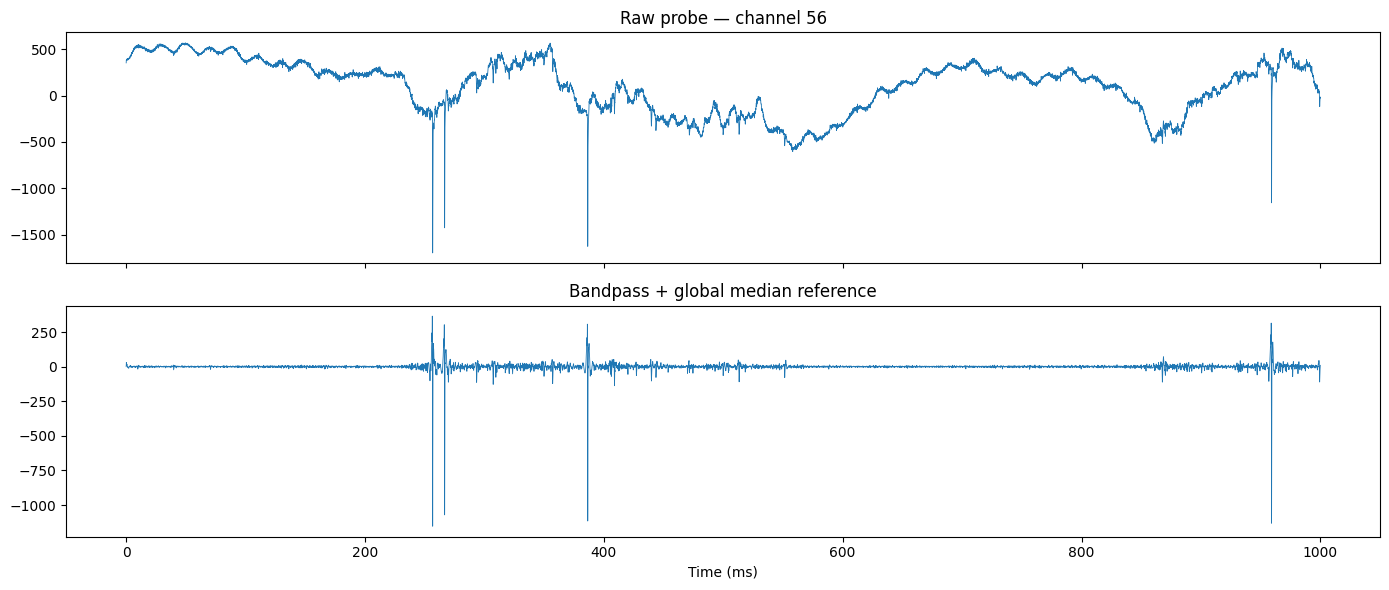

In [4]:
probe_end = min(num_frames, int(round(fs)))
raw_probe_uv = recording.get_traces(
    start_frame=0,
    end_frame=probe_end,
    return_in_uV=True,
)
if raw_probe_uv.shape != (probe_end, num_channels) or not np.isfinite(raw_probe_uv).all():
    raise ValueError(f"Unexpected/non-finite voltage-scaled probe: {raw_probe_uv.shape}")
print(f"Raw probe in uV: shape={raw_probe_uv.shape}, min={raw_probe_uv.min():.3f}, max={raw_probe_uv.max():.3f}")

recording_bp = si.bandpass_filter(recording, freq_min=300, freq_max=3000)
recording_preprocessed = si.common_reference(
    recording_bp,
    reference="global",
    operator="median",
)

processed_probe_uv = recording_preprocessed.get_traces(
    start_frame=0,
    end_frame=probe_end,
    return_in_uV=True,
)
if not np.isfinite(processed_probe_uv).all():
    raise ValueError("Preprocessed probe contains NaN or infinite values.")
print(f"Filtered + CMR in uV: min={processed_probe_uv.min():.3f}, max={processed_probe_uv.max():.3f}")

probe_channel = int(np.argmax(np.max(np.abs(processed_probe_uv), axis=0)))
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
time_ms = np.arange(probe_end) / fs * 1000
axes[0].plot(time_ms, raw_probe_uv[:, probe_channel], linewidth=0.6)
axes[0].set_title(f"Raw probe — channel {channel_ids[probe_channel]}")
axes[1].plot(time_ms, processed_probe_uv[:, probe_channel], linewidth=0.6)
axes[1].set_title("Bandpass + global median reference")
axes[1].set_xlabel("Time (ms)")
plt.tight_layout()
plt.show()

## 3. Build unit classes and waveform-derived box templates

Class IDs follow the sorting unit order. Box extents reuse the mean-waveform threshold convention from the previous dataset maker, after reordering channels into the same image-row order. The stored mean waveforms are used for box geometry only; the actual images below come from single recording events.

In [5]:
unit_boxes = {}
computed_peak_channel = {}

for unit_id, class_id in unit_to_class.items():
    waveforms = sorting.get_property("mean_waveform_all_channels_filt", [unit_id])
    if waveforms is None or len(waveforms) == 0 or waveforms[0] is None:
        raise KeyError(
            f"Unit {unit_id!r} has no mean_waveform_all_channels_filt property; "
            "cannot reproduce the existing waveform-derived YOLO boxes."
        )
    waveform = np.asarray(waveforms[0])
    if waveform.ndim != 2:
        raise ValueError(f"Unexpected waveform shape for unit {unit_id!r}: {waveform.shape}")
    if waveform.shape[1] == num_channels:
        waveform = waveform[:, channel_order]
    elif waveform.shape[0] == num_channels:
        waveform = waveform[channel_order, :].T
    else:
        raise ValueError(f"Waveform for unit {unit_id!r} has no {num_channels}-channel axis: {waveform.shape}")

    if not np.isfinite(waveform).all():
        raise ValueError(f"Mean waveform for unit {unit_id!r} contains non-finite values.")
    abs_waveform = np.abs(waveform)
    if abs_waveform.max() <= 0:
        raise ValueError(f"Mean waveform for unit {unit_id!r} has zero amplitude.")
    peak_time, peak_channel = np.unravel_index(np.argmax(abs_waveform), abs_waveform.shape)
    threshold = BOX_THRESHOLD * float(abs_waveform.max())
    time_indices, channel_indices_in_image = np.where(abs_waveform >= threshold)
    unit_boxes[class_id] = {
        "peak_time": int(peak_time),
        "peak_channel": int(peak_channel),
        "left": int(peak_time - time_indices.min()),
        "right": int(time_indices.max() - peak_time),
        "top": int(peak_channel - channel_indices_in_image.min()),
        "bottom": int(channel_indices_in_image.max() - peak_channel),
    }
    computed_peak_channel[class_id] = int(peak_channel)

print(f"Waveform box templates: {len(unit_boxes)}")
print("First template:", unit_boxes[0])

Waveform box templates: 100
First template: {'peak_time': 41, 'peak_channel': 112, 'left': 3, 'right': 7, 'top': 8, 'bottom': 14}


## 4. Select spikes and create centered 128×128 images

The selected event is placed at image column 64 (window start = spike frame − 64). All sorted spikes with complete boxes inside the image are labeled. A partial spike near an edge stays in the image but is not labeled; a crop is only skipped when its centered target spike itself cannot be fully labeled. Candidate windows are sampled from all sorted events in the pilot interval, up to `PILOT_EVENTS_PER_UNIT` examples per class and labeled-spike count. Crops use fixed chronological 70% train / 15% validation / 15% test intervals, and the full time window must fit inside one interval.

In [7]:

def extract_spike_image(spike_frame):
    window_start = int(spike_frame) - WINDOW_SIZE // 2
    window_end = window_start + WINDOW_SIZE
    if window_start < 0 or window_end > num_frames:
        raise ValueError(f"Spike frame {spike_frame} is too close to a recording boundary.")
    traces_uv = recording_preprocessed.get_traces(
        start_frame=window_start,
        end_frame=window_end,
        return_in_uV=True,
    )
    scale_uv = np.percentile(np.abs(traces_uv),99.0,)
    if not np.isfinite(traces_uv).all():
        raise ValueError(f"Non-finite values in event window for frame {spike_frame}.")
    window = traces_uv[:, channel_order].T
    clipped = np.clip(window, -scale_uv, scale_uv)

    image = np.rint((clipped / scale_uv + 1.0) * 127.5).astype(np.uint8)
    #clipped = np.clip(window, -IMAGE_CLIP_UV, IMAGE_CLIP_UV)
    #image = np.rint((clipped / IMAGE_CLIP_UV + 1.0) * 127.5)
    #return image.astype(np.uint8), window_start, window

def extract_spike_image2(spike_frame, window_start=None):
    if window_start is None:
        window_start = int(spike_frame) - WINDOW_SIZE // 2
    window_end = window_start + WINDOW_SIZE
    if window_start < 0 or window_end > num_frames:
        raise ValueError(f"Window for spike {spike_frame} leaves the recording.")
    traces_uv = recording_preprocessed.get_traces(
        start_frame=window_start, end_frame=window_end, return_in_uV=True,
    )
    tr = recording_preprocessed.get_traces(
    start_frame=int(60 * fs), end_frame=int(70 * fs), return_in_uV=True
    )
    noise_sigma = np.median(np.abs(tr - np.median(tr))) / 0.6745
    IMAGE_CLIP_UV = round(5.0 * noise_sigma / 5) * 5   # e.g. noise_sigma ≈ 7 µV -> 35

    if not np.isfinite(traces_uv).all():
        raise ValueError(f"Non-finite values in window for frame {spike_frame}.")
    window = traces_uv[:, channel_order].T
    clipped = np.clip(window, -IMAGE_CLIP_UV, IMAGE_CLIP_UV)
    image = np.rint((clipped / IMAGE_CLIP_UV + 1.0) * 127.5).astype(np.uint8)
    return image, window_start, window

def yolo_box(spike_frame, class_id, window_start):
    box = unit_boxes[int(class_id)]
    x0 = int(spike_frame) - window_start - box["left"]
    x1 = int(spike_frame) - window_start + box["right"] + 1
    y0 = box["peak_channel"] - box["top"]
    y1 = box["peak_channel"] + box["bottom"] + 1
    if (
        x0 < IMAGE_EDGE_MARGIN_PIXELS
        or x1 > WINDOW_SIZE - IMAGE_EDGE_MARGIN_PIXELS
        or y0 < IMAGE_EDGE_MARGIN_PIXELS
        or y1 > num_channels - IMAGE_EDGE_MARGIN_PIXELS
    ):
        raise ValueError(f"Spike box is truncated or touches the edge margin for frame={spike_frame}, class={class_id}")
    return [
        int(class_id),
        ((x0 + x1) / 2) / WINDOW_SIZE,
        ((y0 + y1) / 2) / num_channels,
        (x1 - x0) / WINDOW_SIZE,
        (y1 - y0) / num_channels,
    ], (x0, y0, x1, y1)

def get_window_labels(spike_frame, window_start):
    window_end = window_start + WINDOW_SIZE
    first = np.searchsorted(event_frames, window_start - max_box_right, side="left")
    stop = np.searchsorted(event_frames, window_end + max_box_left, side="left")
    labels = []
    partial_events = []
    for event_frame, event_class in events[first:stop]:
        event_frame = int(event_frame)
        event_class = int(event_class)
        box = unit_boxes[event_class]
        x0 = event_frame - window_start - box["left"]
        x1 = event_frame - window_start + box["right"] + 1
        if x1 <= 0 or x0 >= WINDOW_SIZE:
            continue
        y0 = box["peak_channel"] - box["top"]
        y1 = box["peak_channel"] + box["bottom"] + 1
        if (
            x0 < IMAGE_EDGE_MARGIN_PIXELS
            or x1 > WINDOW_SIZE - IMAGE_EDGE_MARGIN_PIXELS
            or y0 < IMAGE_EDGE_MARGIN_PIXELS
            or y1 > num_channels - IMAGE_EDGE_MARGIN_PIXELS
        ):
            partial_events.append((event_frame, event_class))
            continue
        label, pixel_box = yolo_box(event_frame, event_class, window_start)
        labels.append((event_frame, event_class, label, pixel_box))
    return labels, partial_events

pilot_start_frame = int(round(PILOT_START_SECONDS * fs))
pilot_end_frame = min(num_frames, int(round((PILOT_START_SECONDS + PILOT_DURATION_SECONDS) * fs)))
if pilot_start_frame < 0 or pilot_start_frame >= pilot_end_frame:
    raise ValueError("Pilot interval is outside the recording; adjust PILOT_START_SECONDS/DURATION.")
if not 0.0 < TRAIN_FRACTION < 1.0 or not 0.0 < VAL_FRACTION < 1.0:
    raise ValueError("Train and validation fractions must be between 0 and 1.")
if TRAIN_FRACTION + VAL_FRACTION >= 1.0:
    raise ValueError("Train and validation fractions must sum to less than 1.")

pilot_events = events[(event_frames >= pilot_start_frame) & (event_frames < pilot_end_frame)]
pilot_span = pilot_end_frame - pilot_start_frame
train_end_frame = pilot_start_frame + int(round(pilot_span * TRAIN_FRACTION))
val_end_frame = pilot_start_frame + int(round(pilot_span * (TRAIN_FRACTION + VAL_FRACTION)))
split_intervals = {
    "train": (pilot_start_frame, train_end_frame),
    "val": (train_end_frame, val_end_frame),
    "test": (val_end_frame, pilot_end_frame),
}
max_box_left = max(box["left"] for box in unit_boxes.values())
max_box_right = max(box["right"] for box in unit_boxes.values())
candidate_groups = {}
recording_boundary_count = 0
split_boundary_count = 0
unlabelable_center_count = 0
ignored_partial_spike_count = 0

for frame, class_id in pilot_events:
    frame = int(frame)
    class_id = int(class_id)
    if not (WINDOW_SIZE // 2 <= frame <= num_frames - WINDOW_SIZE // 2):
        recording_boundary_count += 1
        continue
    window_start = frame - WINDOW_SIZE // 2
    window_end = window_start + WINDOW_SIZE
    split_name = next(
        (name for name, (split_start, split_end) in split_intervals.items()
         if split_start <= window_start and window_end <= split_end),
        None,
    )
    if split_name is None:
        split_boundary_count += 1
        continue
    labels, partial_events = get_window_labels(frame, window_start)
    ignored_partial_spike_count += len(partial_events)
    if not any(event_frame == frame and event_class == class_id for event_frame, event_class, _, _ in labels):
        unlabelable_center_count += 1
        continue
    candidate_groups.setdefault((class_id, len(labels)), []).append((frame, class_id, labels, split_name))

eligible_pilot_events = []
for candidates in candidate_groups.values():
    if len(candidates) > PILOT_EVENTS_PER_UNIT:
        indices = np.linspace(0, len(candidates) - 1, PILOT_EVENTS_PER_UNIT, dtype=int)
        candidates = [candidates[index] for index in indices]
    eligible_pilot_events.extend(candidates)
eligible_pilot_events.sort(key=lambda item: item[0])
multi_spike_windows = sum(len(labels) > 1 for _, _, labels, _ in eligible_pilot_events)
print(f"Sorted events in pilot interval: {len(pilot_events)}")
print(f"Candidate crops retained after edge/split checks and per-class/count sampling: {len(eligible_pilot_events)}")
print(f"Excluded: recording boundaries={recording_boundary_count}, split boundaries={split_boundary_count}, centered spikes not fully labelable={unlabelable_center_count}")
print(f"Partial neighboring spikes left unlabelled: {ignored_partial_spike_count}")
print(f"Retained crops with multiple complete labels: {multi_spike_windows}")
traces_uv = recording_preprocessed.get_traces(start_frame=window_start,end_frame=window_end,return_in_uV=True,)

print(f"Global robust scale: {scale_uv:.2f} µV")


Sorted events in pilot interval: 130171
Candidate crops retained after edge/split checks and per-class/count sampling: 3666
Excluded: recording boundaries=0, split boundaries=4, centered spikes not fully labelable=4171
Partial neighboring spikes left unlabelled: 228601
Retained crops with multiple complete labels: 3415


NameError: name 'scale_uv' is not defined

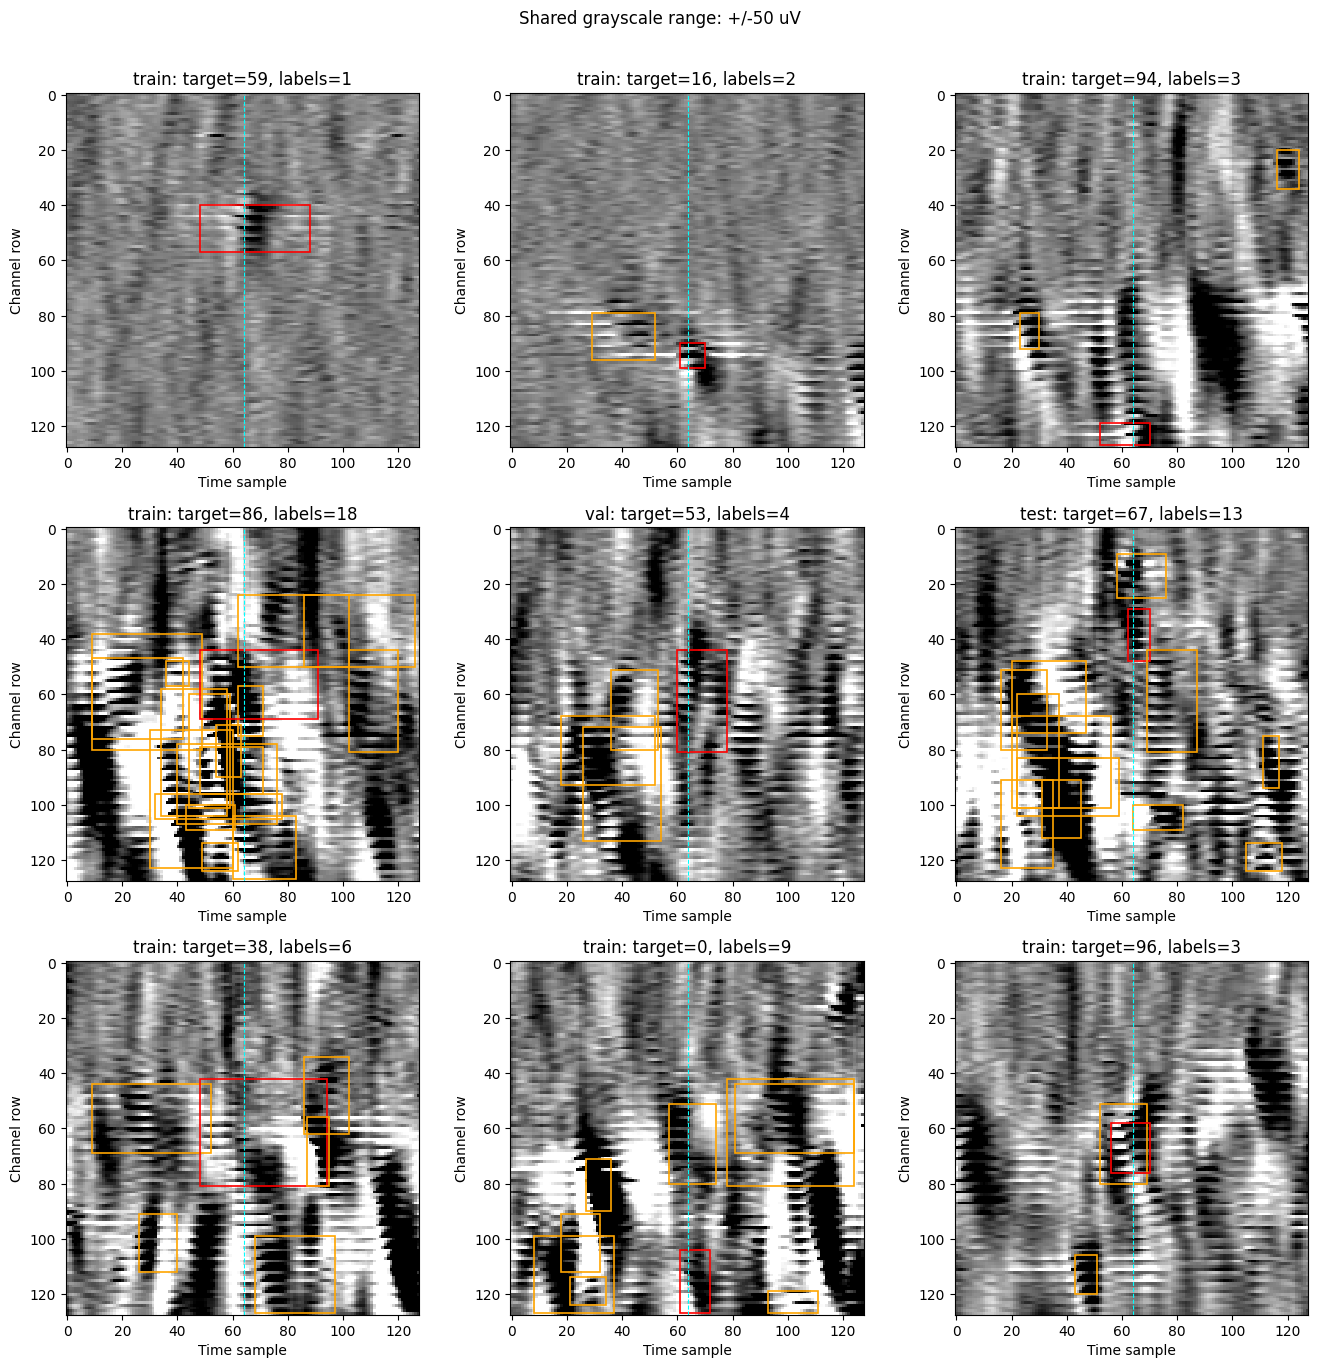

Previewed 9 of 3666 complete-spike crops
Clipped-pixel fraction per preview: [0.0003, 0.0012, 0.0082, 0.0852, 0.0085, 0.0626, 0.0448, 0.0789, 0.0163]
Mean clipped-pixel fraction: 3.40%


In [ ]:
preview_rows = []
preview_keys = set()
for count_matches in (
    [item for item in eligible_pilot_events if len(item[2]) == 1],
    [item for item in eligible_pilot_events if len(item[2]) == 2],
    [item for item in eligible_pilot_events if len(item[2]) == 3],
    [item for item in eligible_pilot_events if len(item[2]) >= 4],
):
    if count_matches:
        item = count_matches[len(count_matches) // 2]
        preview_rows.append(item)
        preview_keys.add((item[0], item[1]))
for split_name in ("train", "val", "test"):
    split_matches = [item for item in eligible_pilot_events if item[3] == split_name]
    if split_matches and not any(item[3] == split_name for item in preview_rows):
        item = split_matches[len(split_matches) // 2]
        if (item[0], item[1]) not in preview_keys:
            preview_rows.append(item)
            preview_keys.add((item[0], item[1]))
remaining_count = 9 - len(preview_rows)
if remaining_count > 0:
    for index in np.linspace(0, len(eligible_pilot_events) - 1, min(len(eligible_pilot_events), remaining_count * 2), dtype=int):
        item = eligible_pilot_events[index]
        if (item[0], item[1]) not in preview_keys:
            preview_rows.append(item)
            preview_keys.add((item[0], item[1]))
        if len(preview_rows) == 9:
            break
preview_count = len(preview_rows)
ncols = min(3, preview_count)
nrows = int(np.ceil(preview_count / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 4.5 * nrows), squeeze=False)
preview_clip_fractions = []

for ax, (preview_frame, preview_class, preview_labels, split_name) in zip(axes.flat, preview_rows):
    preview_image, preview_start, preview_window_uv = extract_spike_image2(preview_frame)
    assert len(preview_labels) >= 1
    assert preview_image.shape == (128, 128)
    assert preview_image.dtype == np.uint8
    assert preview_frame - preview_start == WINDOW_SIZE // 2

    ax.imshow(preview_image, cmap="gray", vmin=0, vmax=255, origin="upper", interpolation="nearest")
    for event_frame, event_class, _, (x0, y0, x1, y1) in preview_labels:
        color = "red" if event_frame == preview_frame and event_class == preview_class else "orange"
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, linewidth=1.2))
    ax.axvline(WINDOW_SIZE // 2, color="cyan", linestyle="--", linewidth=0.8)
    ax.set_title(f"{split_name}: target={preview_class}, labels={len(preview_labels)}")
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Channel row")
    preview_clip_fractions.append(np.mean(np.abs(preview_window_uv) >= IMAGE_CLIP_UV))

for ax in axes.flat[preview_count:]:
    ax.set_visible(False)
fig.suptitle(f"Shared grayscale range: +/-{IMAGE_CLIP_UV:g} uV", y=1.01)
plt.tight_layout()
plt.show()

print(f"Previewed {preview_count} of {len(eligible_pilot_events)} complete-spike crops")
print(f"Clipped-pixel fraction per preview: {np.array(preview_clip_fractions).round(4).tolist()}")
print(f"Mean clipped-pixel fraction: {np.mean(preview_clip_fractions):.2%}")

## 5. Build staged datasets with fixed chronological splits

This cell prints split and class-coverage summaries, then writes three separate YOLO datasets. Stage 1 includes exactly one labeled spike per image; Stage 2 includes one to three; Stage 3 includes any positive count. Partial edge spikes remain visible but are omitted from the label file. If a stage or split has no examples, the exporter reports it and continues; increase `PILOT_DURATION_SECONDS` or adjust the time interval before attempting training on an empty split.

In [78]:
stage_specs = {
    "stage1_single_spike": (1, 1),
    "stage2_up_to_3_spikes": (1, 3),
    "stage3_any_spike_count": (1, None),
}
split_names = ("train", "val", "test")
stage_items = {}

for stage_name, (min_spikes, max_spikes) in stage_specs.items():
    stage_items[stage_name] = [
        item for item in eligible_pilot_events
        if len(item[2]) >= min_spikes and (max_spikes is None or len(item[2]) <= max_spikes)
    ]
    print(f"\n{stage_name}")
    for split_name in split_names:
        split_items = [item for item in stage_items[stage_name] if item[3] == split_name]
        image_counts = {}
        for item in split_items:
            image_counts[len(item[2])] = image_counts.get(len(item[2]), 0) + 1
        class_ids = sorted({event_class for item in split_items for _, event_class, _, _ in item[2]})
        print(f"  {split_name}: images={len(split_items)}, classes={len(class_ids)}/{len(unit_ids)}, images_by_label_count={image_counts}")

for stage_name, items in stage_items.items():
    if not items:
        print(f"WARNING: {stage_name} has no images; expand the pilot interval before training this stage.")
    empty_splits = [split_name for split_name in split_names if not any(item[3] == split_name for item in items)]
    if empty_splits:
        print(f"WARNING: {stage_name} has empty splits {empty_splits}; expand the pilot interval before training.")

build_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
stage_root = OUTPUT_DIR.parent / f"nwb_spike_centered_stages_{build_id}"
class_names = [str(unit_id) for unit_id in unit_ids]
print(f"\nWriting immutable staged build to {stage_root.resolve()}")

for stage_name, items in stage_items.items():
    stage_dir = stage_root / stage_name
    manifest_rows = []
    for split_name in split_names:
        split_items = [item for item in items if item[3] == split_name]
        (stage_dir / "images" / split_name).mkdir(parents=True, exist_ok=True)
        (stage_dir / "labels" / split_name).mkdir(parents=True, exist_ok=True)

        for index, (spike_frame, class_id, window_labels, _) in enumerate(split_items):
            image, window_start, _ = extract_spike_image(spike_frame)
            stem = f"{split_name}_{index:06d}"
            image_path = stage_dir / "images" / split_name / f"{stem}.png"
            label_path = stage_dir / "labels" / split_name / f"{stem}.txt"
            Image.fromarray(image).save(image_path)
            label_path.write_text(
                "".join(
                    f"{label[0]} {label[1]:.6f} {label[2]:.6f} {label[3]:.6f} {label[4]:.6f}\n"
                    for _, _, label, _ in window_labels
                ),
                encoding="utf-8",
            )
            manifest_rows.append({
                "split": split_name,
                "image": str(image_path.relative_to(stage_dir)),
                "label": str(label_path.relative_to(stage_dir)),
                "center_unit_id": str(unit_ids[class_id]),
                "center_class_id": class_id,
                "center_spike_frame": spike_frame,
                "center_spike_time_seconds": spike_frame / fs,
                "window_start_frame": window_start,
                "window_end_frame": window_start + WINDOW_SIZE,
                "labeled_spike_count": len(window_labels),
                "labeled_class_ids": ",".join(str(event_class) for _, event_class, _, _ in window_labels),
            })

    with (stage_dir / "manifest.csv").open("w", newline="", encoding="utf-8") as manifest_file:
        manifest_fields = [
            "split", "image", "label", "center_unit_id", "center_class_id",
            "center_spike_frame", "center_spike_time_seconds", "window_start_frame",
            "window_end_frame", "labeled_spike_count", "labeled_class_ids",
        ]
        writer = csv.DictWriter(manifest_file, fieldnames=manifest_fields)
        writer.writeheader()
        writer.writerows(manifest_rows)
    yaml_names = "\n".join(f"  {class_id}: {json.dumps(name)}" for class_id, name in enumerate(class_names))
    (stage_dir / "data.yaml").write_text(
        f"path: {stage_dir.resolve()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n{yaml_names}\n",
        encoding="utf-8",
    )
    print(f"{stage_name}: wrote {len(manifest_rows)} images; manifest={stage_dir / 'manifest.csv'}")

print(f"Completed all three stages in {stage_root.resolve()}")


stage1_single_spike
  train: images=165, classes=84/100, images_by_label_count={1: 165}
  val: images=15, classes=15/100, images_by_label_count={1: 15}
  test: images=71, classes=70/100, images_by_label_count={1: 71}

stage2_up_to_3_spikes
  train: images=503, classes=92/100, images_by_label_count={3: 172, 1: 165, 2: 166}
  val: images=43, classes=48/100, images_by_label_count={2: 17, 3: 11, 1: 15}
  test: images=229, classes=84/100, images_by_label_count={1: 71, 2: 78, 3: 80}

stage3_any_spike_count
  train: images=2439, classes=95/100, images_by_label_count={6: 170, 8: 173, 7: 175, 10: 157, 9: 164, 11: 155, 5: 178, 4: 170, 3: 172, 1: 165, 2: 166, 12: 146, 14: 114, 13: 123, 16: 66, 15: 91, 17: 27, 18: 18, 19: 8, 20: 1}
  val: images=196, classes=91/100, images_by_label_count={11: 13, 15: 8, 2: 17, 10: 20, 5: 5, 9: 6, 12: 8, 16: 8, 3: 11, 4: 9, 1: 15, 8: 13, 7: 9, 14: 22, 6: 14, 13: 17, 17: 1}
  test: images=1031, classes=90/100, images_by_label_count={12: 63, 13: 50, 8: 75, 4: 85, 1:

KeyboardInterrupt: 

## Sanity-check checklist before training

- Confirm the plotted raw and processed traces have plausible voltage ranges and no obvious preprocessing artifacts.
- Confirm the spike is visually centered at column 64 and the filtered-voltage image has a gray background with localized waveform structure; adjust `IMAGE_CLIP_UV` if clipping is common or the event is too faint.
- Confirm the red waveform-derived box encloses the visible event. If not, inspect `BOX_THRESHOLD` and the stored mean-waveform orientation before changing box logic.
- Check that every complete sorted spike visible in a crop has a YOLO row and that the preview marks the centered target in red and other spikes in orange.
- Partial edge spikes remain in the image but are intentionally omitted from the labels; this can create unlabeled spike signal, so inspect examples before training.
- Check the printed image counts and class coverage for every stage and split. A short pilot can have missing classes in validation/test; expand the time interval before training if needed.
- The staged folders are cumulative by design. Keep the validation/test intervals fixed when comparing model progression across stages.

    The pilot uses filtered recording crops (not averages), so real spikes will vary more than the clean mean waveforms. Inspect all previewed boxes and clipping metrics before scaling up.